In [1]:
!apt-get -qq install -y tesseract-ocr
%pip install -q pytesseract requests

In [3]:
import os
import re
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pytesseract
import requests
from pathlib import Path
from getpass import getpass
from PIL import Image
from IPython.display import display
from google.colab import files


def upload_one_image(message):
    print(message)
    uploaded = files.upload()
    names = [name for name in uploaded if name.lower().endswith(('.png', '.jpg', '.jpeg'))]
    if not names:
        raise ValueError('Upload at least one .jpg, .jpeg, or .png image, then rerun this cell.')
    return names[0]


def read_image_bgr(path):
    image = cv2.imread(str(path))
    if image is None:
        raise ValueError(f'Could not load image: {path}')
    return image


def show_bgr(image, title, figsize=(7, 5)):
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
    plt.show()

print('Imports ready.')

Imports ready.


In [4]:
MEDICINE_ENDPOINT_ID = '4110a1ed-cf96-429c-bb61-4cdfc3fce6b0'
FACE_ENDPOINT_ID = '191e0749-66d3-472e-889d-2f2d99523c25'

LANDINGAI_API_KEY = os.environ.get('LANDINGAI_API_KEY', '').strip()
if not LANDINGAI_API_KEY:
    LANDINGAI_API_KEY = getpass('Enter your LandingLens API key (hidden): ').strip()
if not LANDINGAI_API_KEY:
    raise ValueError('An API key is required to call your deployed endpoints.')

print('Endpoint IDs configured. API key stored only in this notebook session.')

Enter your LandingLens API key (hidden): ··········
Endpoint IDs configured. API key stored only in this notebook session.


In [5]:
INFERENCE_URL = 'https://predict.app.landing.ai/inference/v1/predict'


def call_landinglens(image_path, endpoint_id, api_key=LANDINGAI_API_KEY, timeout=90):
    image_path = Path(image_path)
    if not image_path.is_file():
        raise FileNotFoundError(f'Image not found: {image_path}')
    if not endpoint_id or not api_key:
        raise ValueError('Endpoint ID and API key are required.')

    try:
        with image_path.open('rb') as f:
            response = requests.post(
                INFERENCE_URL,
                params={'endpoint_id': endpoint_id},
                headers={'apikey': api_key},
                files={'file': (image_path.name, f)},
                timeout=timeout,
            )
        response.raise_for_status()
    except requests.RequestException as exc:
        code = getattr(getattr(exc, 'response', None), 'status_code', None)
        if code in (401, 403):
            raise RuntimeError('API authentication or endpoint permissions failed. Check your API key.') from exc
        if code == 404:
            raise RuntimeError('Endpoint was not found. Check the deployed endpoint ID.') from exc
        raise RuntimeError(f'LandingLens request failed (HTTP status: {code}).') from exc

    try:
        body = response.json()
    except ValueError as exc:
        raise RuntimeError('API did not return JSON.') from exc
    if not isinstance(body, dict):
        raise RuntimeError('Unexpected non-object response from API.')
    return body


def save_api_response(result, filename):
    with open(filename, 'w', encoding='utf-8') as f:
        json.dump(result, f, indent=2)
    print('Saved response:', filename)


def classification_prediction(result):
    """Return (label, score) from a ClassificationPrediction; never mistake OK for emotion."""
    p = result.get('predictions')
    if isinstance(p, dict) and 'labelName' in p:
        return str(p['labelName']), float(p.get('score', 0.0))
    if isinstance(p, list):
        items = [x for x in p if isinstance(x, dict) and 'labelName' in x]
        if items:
            best = max(items, key=lambda x: float(x.get('score', 0.0)))
            return str(best['labelName']), float(best.get('score', 0.0))
    return None, None

print('HTTP API helper ready.')

HTTP API helper ready.


# Q1. Cognitive Assistant for Reading Labels on Medicine Bottles


Q1: Upload a NEW medicine bottle image (.jpg/.png):


Saving test.jpeg to test.jpeg


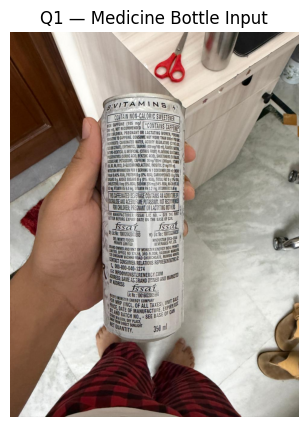

In [8]:
medicine_path = upload_one_image('Q1: Upload a NEW medicine bottle image (.jpg/.png):')
medicine_image = read_image_bgr(medicine_path)
show_bgr(medicine_image, 'Q1 — Medicine Bottle Input')

In [9]:
medicine_api_response = call_landinglens(
    medicine_path, MEDICINE_ENDPOINT_ID
)
save_api_response(medicine_api_response, 'medicine_landinglens_response.json')

print('Response type:', medicine_api_response.get('type'))
print('Backbone type:', medicine_api_response.get('backbonetype'))
print('Top-level prediction:', medicine_api_response.get('predictions'))

medicine_image_label, medicine_image_score = classification_prediction(medicine_api_response)
if medicine_image_label is not None:
    print(f'Image-level model output: {medicine_image_label} (score: {medicine_image_score:.2%})')
    if medicine_image_label.upper() in ('OK', 'NG'):
        print('NOTE: OK/NG is an image status; it is not OCR text or a medicine name.')

Saved response: medicine_landinglens_response.json
Response type: ClassificationPrediction
Backbone type: ObjectDetectionPrediction
Top-level prediction: {'score': 0.9539214968681335, 'labelName': 'NG', 'labelIndex': 1}
Image-level model output: NG (score: 95.39%)
NOTE: OK/NG is an image status; it is not OCR text or a medicine name.


In [11]:
import json

print(json.dumps(
    medicine_api_response.get("backbonepredictions"),
    indent=2
))

{
  "6250da4c-5db6-46ee-bc63-beb3ee527aa6": {
    "score": 0.9539214968681335,
    "labelName": "Medicine_Label",
    "labelIndex": 1,
    "coordinates": {
      "xmin": 312,
      "ymin": 246,
      "xmax": 573,
      "ymax": 1017
    },
    "defect_id": 536470
  }
}


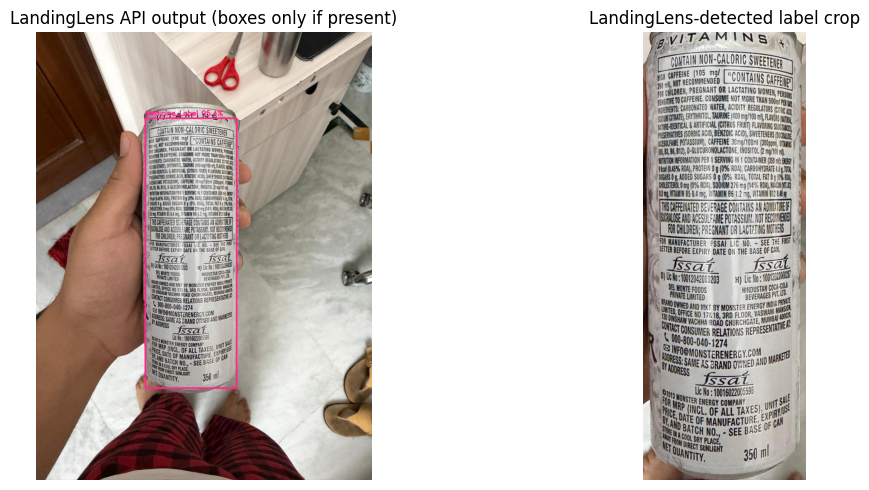

Crop source: LandingLens-detected label crop


In [12]:
from numbers import Real


def _prediction_dicts(value, depth=0):
    """Find detection records inside nested dictionaries/lists, but ignore image-only predictions."""
    if depth > 5 or value is None:
        return []
    if isinstance(value, list):
        out = []
        for v in value:
            out.extend(_prediction_dicts(v, depth + 1))
        return out
    if isinstance(value, dict):
        box_keys = ('coordinates', 'bbox', 'bboxes', 'bounding_box', 'box')
        if any(k in value for k in box_keys):
            return [value]
        out = []
        for v in value.values():
            if isinstance(v, (list, dict)):
                out.extend(_prediction_dicts(v, depth + 1))
        return out
    return []


def _read_xyxy(raw, width, height):
    if isinstance(raw, dict):
        if all(k in raw for k in ('xmin', 'ymin', 'xmax', 'ymax')):
            b = [raw[k] for k in ('xmin', 'ymin', 'xmax', 'ymax')]
        elif all(k in raw for k in ('x1', 'y1', 'x2', 'y2')):
            b = [raw[k] for k in ('x1', 'y1', 'x2', 'y2')]
        elif all(k in raw for k in ('x', 'y', 'width', 'height')):
            b = [raw['x'], raw['y'], raw['x'] + raw['width'], raw['y'] + raw['height']]
        else:
            return None
    elif isinstance(raw, (list, tuple)) and len(raw) == 4:
        b = list(raw)  # xmin, ymin, xmax, ymax
    else:
        return None
    try:
        b = [float(z) for z in b]
    except (TypeError, ValueError):
        return None
    if not all(np.isfinite(z) for z in b):
        return None
    if min(b) >= 0 and max(b) <= 1:
        b = [b[0] * width, b[1] * height, b[2] * width, b[3] * height]
    x1, y1, x2, y2 = b
    x1, y1 = max(0, min(width, x1)), max(0, min(height, y1))
    x2, y2 = max(0, min(width, x2)), max(0, min(height, y2))
    if x2 <= x1 or y2 <= y1:
        return None
    return tuple(int(round(z)) for z in (x1, y1, x2, y2))


def object_boxes(api_result, image_shape):
    height, width = image_shape[:2]
    # The response may contain a list/dict of object records; image classification has none.
    candidates = _prediction_dicts(api_result.get('backbonepredictions'))
    if not candidates:
        candidates = _prediction_dicts(api_result.get('predictions'))
    boxes = []
    for p in candidates:
        coords = next((p[k] for k in ('coordinates', 'bbox', 'bboxes', 'bounding_box', 'box') if k in p), None)
        box = _read_xyxy(coords, width, height)
        if box is None:
            continue
        try:
            score = float(p.get('score', p.get('confidence', 0.0)))
        except (TypeError, ValueError):
            score = 0.0
        boxes.append({
            'box': box,
            'label': str(p.get('labelName', p.get('label', 'Label'))),
            'score': score,
        })
    return sorted(boxes, key=lambda v: v['score'], reverse=True)


medicine_boxes = object_boxes(medicine_api_response, medicine_image.shape)
medicine_annotated = medicine_image.copy()

for b in medicine_boxes:
    x1, y1, x2, y2 = b['box']
    cv2.rectangle(medicine_annotated, (x1, y1), (x2, y2), (140, 40, 255), 3)
    cv2.putText(medicine_annotated, f"{b['label']} {b['score']:.1%}",
                (x1, max(25, y1 - 8)), cv2.FONT_HERSHEY_SIMPLEX,
                0.65, (140, 40, 255), 2)

if medicine_boxes:
    x1, y1, x2, y2 = medicine_boxes[0]['box']
    pad = max(3, round(0.02 * max(x2 - x1, y2 - y1)))
    h, w = medicine_image.shape[:2]
    label_crop = medicine_image[max(0, y1-pad):min(h, y2+pad), max(0, x1-pad):min(w, x2+pad)].copy()
    medicine_crop_source = 'LandingLens-detected label crop'
else:
    label_crop = medicine_image.copy()
    medicine_crop_source = 'Full original image (NO API bounding box returned)'
    print('No bounding box returned. OCR will run on the full photo.')

cv2.imwrite('medicine_label_crop_or_full_image.png', label_crop)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].imshow(cv2.cvtColor(medicine_annotated, cv2.COLOR_BGR2RGB))
ax[0].set_title('LandingLens API output (boxes only if present)')
ax[1].imshow(cv2.cvtColor(label_crop, cv2.COLOR_BGR2RGB))
ax[1].set_title(medicine_crop_source)
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()
print('Crop source:', medicine_crop_source)

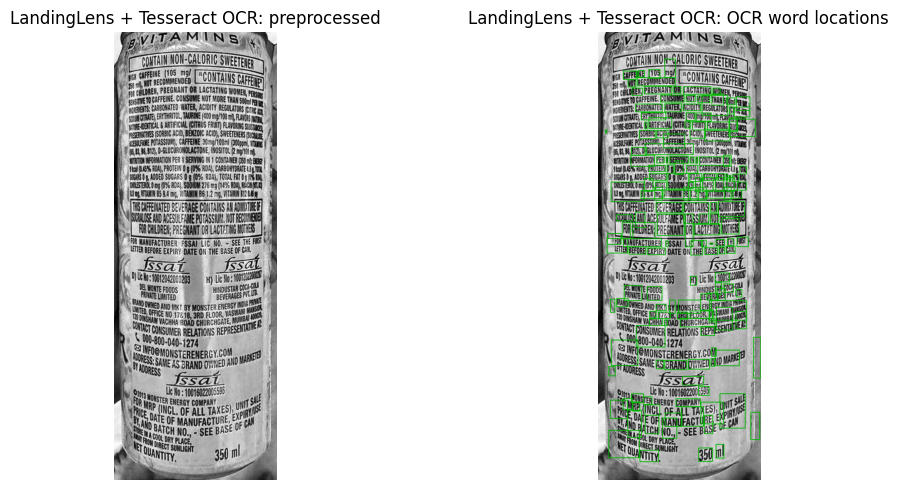

LandingLens + Tesseract OCR: EXTRACTED TEXT
Carre
WoT RECOMMENDED
}
WE (105 a
REN, PREGNANT OR LACTATING Wo
CONSUME NOT MORE THAN
el Pel
CARGONATED WATER, ACIOITY rea tv
ERYTHRITOL,
Ly
B ARTIFICIAL
US FRUIT) FLAVORING sit
(400 mg/t00
> 08 1,
sch SWEETENERS
ss)
CAFFEINE
WFORWATION PER 4 SERVING IN 1 CONTAINER (280
$12), -SLUCURONOLACTONE,
PUTEN 19 (0% ROA), ee
SUGARS
RDA), TOTAL FAT 0 0 10%
(09% ROA},
sm
76 mig (149% ROA) MAD AL
{ira 858.4 mg, VITAMIN BG 1,2 mg, VITAMIN B12 RA
BEVERAGE ier AN ADMD
WAAL
AND
WW NOT
FAR HILDREN; er i {ACT WT
an MANUFACTURER: F:
0, = SEE THE FIN
ma BEFORE EXPIRY “HE BASE OF CAN,
H) Sr
AH COCA
HITE ps
VERA
Ges LR
\
RAN
MKT BY MONSTER ze
CHHA Ri
NO 17248, SRD FLOOR, V
CHUBCHGATE,
‘au
au a
rie REPR
M
ia
AS BRAND OWNED A
us |
on
AL
Mons;
5596
RM
RP
TER COMPANY
INCL
Wie
a
HES) ae
it
EOF MANU
Re
|
NO
Sh
NTITy
450 ml
Mean Tesseract word confidence (approx.): 62.9


In [14]:
def preprocess_label(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    h, w = gray.shape
    scale = min(2.0, 2200 / max(h, w))
    gray = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return clahe.apply(gray)


def run_ocr(image_bgr, description='OCR'):
    processed = preprocess_label(image_bgr)
    data = pytesseract.image_to_data(
        processed, config='--oem 3 --psm 11',
        output_type=pytesseract.Output.DATAFRAME
    )
    data = data.dropna(subset=['text']).copy()
    data['text'] = data['text'].astype(str).str.strip()
    data = data[(data['conf'] >= 25) & (data['text'] != '')]

    if not data.empty:
        ordered = data.sort_values(['block_num', 'par_num', 'line_num', 'word_num'])
        lines = (ordered.groupby(['block_num','par_num','line_num'], sort=False)['text']
                 .apply(lambda words: ' '.join(words)).tolist())
    else:
        lines = []

    annotated = cv2.cvtColor(processed, cv2.COLOR_GRAY2BGR)
    for _, word in data.iterrows():
        x, y, w, h = [int(word[k]) for k in ('left','top','width','height')]
        cv2.rectangle(annotated, (x, y), (x + w, y + h), (0, 180, 0), 2)

    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    ax[0].imshow(processed, cmap='gray')
    ax[0].set_title(f'{description}: preprocessed')
    ax[1].imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    ax[1].set_title(f'{description}: OCR word locations')
    for a in ax:
        a.axis('off')
    plt.tight_layout()
    plt.show()

    text = '\n'.join(lines)
    print(f'{description}: EXTRACTED TEXT')
    print(text if text else 'No readable text detected. Try a sharper, more front-facing image.')
    if not data.empty:
        print('Mean Tesseract word confidence (approx.):', round(float(data['conf'].mean()), 1))
    return lines, text, data


ocr_lines, ocr_text, ocr_data = run_ocr(label_crop, 'LandingLens + Tesseract OCR')

In [15]:
def find_labeled_value(lines, pattern):
    for line in lines:
        match = re.search(pattern, line, flags=re.IGNORECASE)
        if match:
            value = match.group(1).strip(' :-./')
            if value:
                return value
    return 'Not found'


def extract_medicine_fields(lines):
    text = ' '.join(lines)
    strengths = re.findall(r'\b\d+(?:\.\d+)?\s?(?:mg|mcg|g|ml|iu|%)\b', text, flags=re.I)
    strengths = list(dict.fromkeys(strengths))
    skip_starts = (
        'batch', 'exp', 'mfg', 'manufact', 'keep', 'store', 'warning',
        'dosage', 'ingredients', 'contains', 'nutritional', 'nutrition',
        'supplement facts', 'serving', 'net weight', 'directions'
    )
    possible_name = next(
        (line for line in lines if len(line.strip()) >= 3
         and not line.lower().strip().startswith(skip_starts)), 'Not found'
    )
    return {
        'Possible product name (unverified)': possible_name,
        'Strength / volume': ', '.join(strengths) if strengths else 'Not found',
        'Batch number': find_labeled_value(lines, r'\b(?:batch|lot|b\.?\s*no\.?)\s*[:#-]?\s*([A-Za-z0-9/-]+)'),
        'Manufacturing date': find_labeled_value(lines, r'\b(?:mfg|mfd|manufactured|manufacturing)\s*(?:date|dt)?\s*[:#-]?\s*([A-Za-z0-9./-]+)'),
        'Expiry date': find_labeled_value(lines, r'\b(?:exp|expiry|expiration|use before|best before)\s*(?:date|dt)?\s*[:#-]?\s*([A-Za-z0-9./-]+)'),
    }

medicine_fields = extract_medicine_fields(ocr_lines)
print('MEDICINE LABEL DETAILS (UNVERIFIED):')
display(pd.DataFrame(medicine_fields.items(), columns=['Field', 'OCR Result']))
print('\nCognitive assistant:')
if not ocr_lines:
    print('I could not read the label. Please try better lighting and a clearer photo.')
else:
    print('I extracted possible text and label information from this image.')
    print('Please verify all details directly from the bottle or with a pharmacist.')
    print('Do not use these OCR results to choose a medicine or determine a dose.')
print('Source of input to OCR:', medicine_crop_source)

MEDICINE LABEL DETAILS (UNVERIFIED):


,Field,OCR Result
0,Possible product name (unverified),Carre
1,Strength / volume,"400 mg, 858.4 mg, 2 mg, 450 ml"
2,Batch number,Not found
3,Manufacturing date,Not found
4,Expiry date,IRY



Cognitive assistant:
I extracted possible text and label information from this image.
Please verify all details directly from the bottle or with a pharmacist.
Do not use these OCR results to choose a medicine or determine a dose.
Source of input to OCR: LandingLens-detected label crop


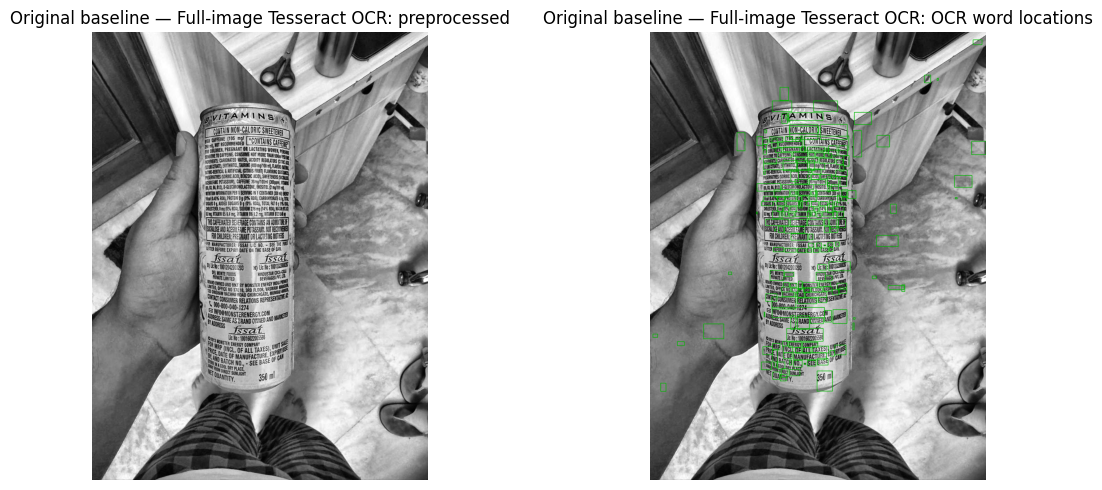

Original baseline — Full-image Tesseract OCR: EXTRACTED TEXT
Lea
J f
%
ee ee
Ey
yi
ye
AMIN
Vo
NOW-CHLORI SWEETER,
= NON-CALORIC
i
Ai
yi
TAFFEINE (105. mg
WoT RECOMMENDED
ff
)
#!
ft
MEN, PREGNANT OR LACTATING W
in|
>
CAFFEINE, CONSUME HOT MORE
THAN
OMEN, Peta
j
* nT: WATER, ACIDITY REGULATORS fap
nt
7
NOTE THIOL, TAURINE (400
US FRUIT)
ACI,
JIC ACID), SWEETEN
ERS
Ss,
=
CAFFEINE 300/007 (pn, Mm
ba
648812, D-GLUCURONOLACTONE, (2 mgt
INFORMATION PEB 4 SERVING IN] 1 CONTAINER RRR)
Shel 0.45% ROA), PROTEIN 0.9 (096 ROA), £8 Tha
le
=
ADDED SUGARS 0 9 (0% RDA), TOTAL FAT 04 \
i
SRS
mg (0% RDA),
276 mg (14% RON AO
‘>
TAIN BS 9,4 ma, VITAMIN B6 1,2 mg, VITAMIN B12 LA
TRSCAFFENATED BEVERAGE CONTAINS AN ADMD AE
)
AND ACESULFAME NOT RSL
PREGNANT OR
LIC. NO. ~ SEE THE
we
BEFORE EXPIRY DATE ON THE BASE OF
Cio OT
a,
FOODS
a,
louis
=
|
RAGE
GENO 1724
AND MKT BY MONSTER ENERGY
SRD FLOOR, VASW
nt
sed *
VACHHA Rt
mt
CHURCHGATE,
MBA
00th
“or
ar RELATIONS REPR
|
INFO@MONSTERENERGY.CO
‘A
ro wae
AS RAND OWNED

,Field,Original OCR Result
0,Possible product name (unverified),Lea
1,Strength / volume,"276 mg, 2 mg"
2,Batch number,Not found
3,Manufacturing date,Not found
4,Expiry date,IRY



Q1 comparison:
LandingLens path: LandingLens-detected label crop
LandingLens + OCR character count: 806
Original full-image OCR character count: 1081
NOTE: More text is not automatically more accurate. Verify against the actual label.


In [16]:
baseline_ocr_lines, baseline_ocr_text, baseline_ocr_data = run_ocr(
    medicine_image, 'Original baseline — Full-image Tesseract OCR'
)
print('\nORIGINAL BASELINE — EXTRACTED FIELDS (UNVERIFIED)')
display(pd.DataFrame(
    extract_medicine_fields(baseline_ocr_lines).items(),
    columns=['Field', 'Original OCR Result']
))

print('\nQ1 comparison:')
print('LandingLens path:', medicine_crop_source)
print('LandingLens + OCR character count:', len(ocr_text))
print('Original full-image OCR character count:', len(baseline_ocr_text))
print('NOTE: More text is not automatically more accurate. Verify against the actual label.')

Q2: Upload a NEW facial-expression photograph (.jpg/.png):


Saving happyyy.jpg to happyyy.jpg


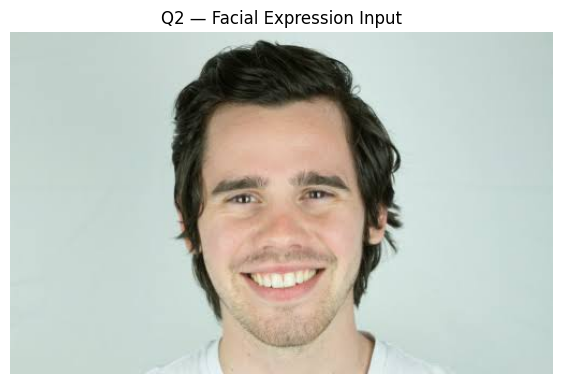

In [17]:
#Q2
face_path = upload_one_image('Q2: Upload a NEW facial-expression photograph (.jpg/.png):')
face_image = read_image_bgr(face_path)
show_bgr(face_image, 'Q2 — Facial Expression Input')

Saved response: face_landinglens_response.json
Response type: ClassificationPrediction
Backbone predictions: None
API predictions: {'score': 0.9811245203018188, 'labelName': 'Happy', 'labelIndex': 2}

Detected facial expression: Happy
Model confidence: 98.11%


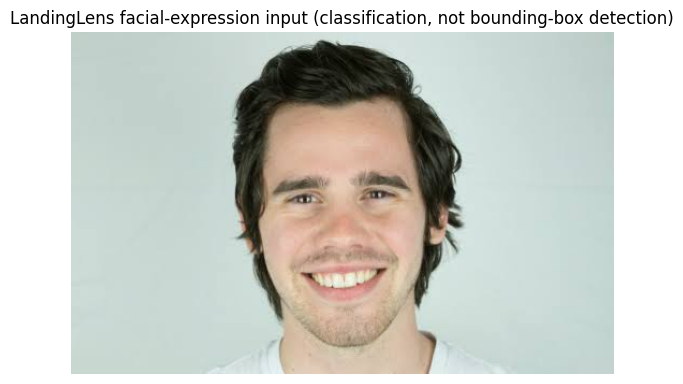

In [18]:
face_api_response = call_landinglens(face_path, FACE_ENDPOINT_ID)
save_api_response(face_api_response, 'face_landinglens_response.json')

print('Response type:', face_api_response.get('type'))
print('Backbone predictions:', face_api_response.get('backbonepredictions'))
print('API predictions:', face_api_response.get('predictions'))

face_label, face_confidence = classification_prediction(face_api_response)

if face_label is not None and face_label.upper() not in ('OK', 'NG'):
    face_expression = face_label.strip().lower()
    print(f'\nDetected facial expression: {face_label}')
    print(f'Model confidence: {face_confidence * 100:.2f}%')
else:
    face_expression = None
    face_confidence = None
    print('No facial-expression classification label was returned.')
    print('Check whether the deployed endpoint is the correct trained face model.')

show_bgr(face_image, 'LandingLens facial-expression input (classification, not bounding-box detection)')

### Q2 — Cognitive assistant response based on the returned expression



In [19]:
assistant_messages = {
    'happy': 'I noticed a smiling expression. Would you like to continue?',
    'sad': 'Your expression looks subdued. Would you prefer a slower, gentler pace?',
    'angry': 'Your expression seems tense. I can explain things step by step if that helps.',
    'fear': 'Your expression looks uneasy. Would a clearer explanation help?',
    'surprise': 'You appear surprised in this picture. Would you like to know more?',
    'disgust': 'Your expression suggests discomfort. Would you like a different approach?',
    'neutral': 'I see a neutral expression. How can I help you today?'
}

expression_aliases = {'surprised': 'surprise', 'fearful': 'fear',
                      'disgusted': 'disgust', 'happiness': 'happy'}

if face_expression is not None:
    normalized = expression_aliases.get(face_expression, face_expression)
    display(pd.DataFrame([{
        'Model': 'Your LandingLens facial endpoint',
        'Expression': face_label,
        'Confidence': f'{face_confidence:.2%}'
    }]))
    print('\nCOGNITIVE ASSISTANT:')
    print(assistant_messages.get(normalized, 'I detected an expression. How can I help you?'))
else:
    print('Cannot produce an expression-specific response without an actual expression label.')

print('Reminder: facial-expression classification does not prove someone is feeling that emotion.')

,Model,Expression,Confidence
0,Your LandingLens facial endpoint,Happy,98.11%



COGNITIVE ASSISTANT:
I noticed a smiling expression. Would you like to continue?
Reminder: facial-expression classification does not prove someone is feeling that emotion.


In [20]:
%pip install -q "transformers>=4.44,<5"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [21]:
import torch
from transformers import pipeline

MODEL_NAME = 'trpakov/vit-face-expression'
device = 0 if torch.cuda.is_available() else -1
emotion_classifier = pipeline(
    task='image-classification', model=MODEL_NAME, device=device
)

face_detector = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
)
if face_detector.empty():
    raise RuntimeError('OpenCV Haar face detector could not be loaded.')
print('Pretrained facial-expression baseline loaded.')
print('Running on:', 'GPU' if device == 0 else 'CPU')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/915 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/343M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/228 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
Device set to use cpu


Pretrained facial-expression baseline loaded.
Running on: CPU


,Face,Detected expression,Model confidence
0,1,happy,0.994


Assistant for face 1: I noticed a smiling expression. Would you like to continue?


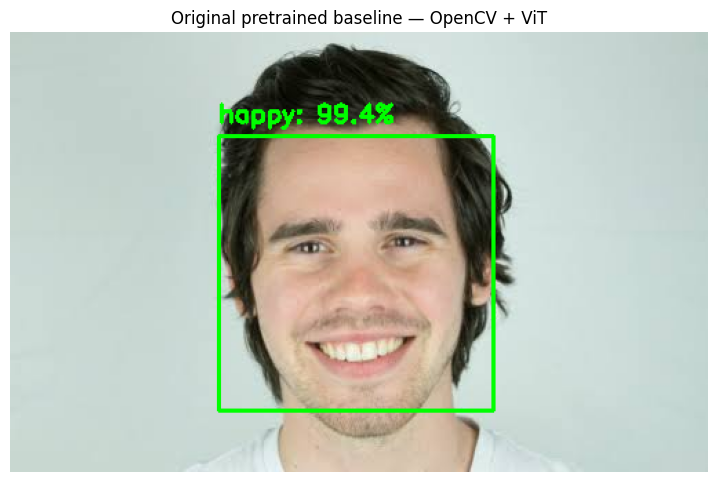

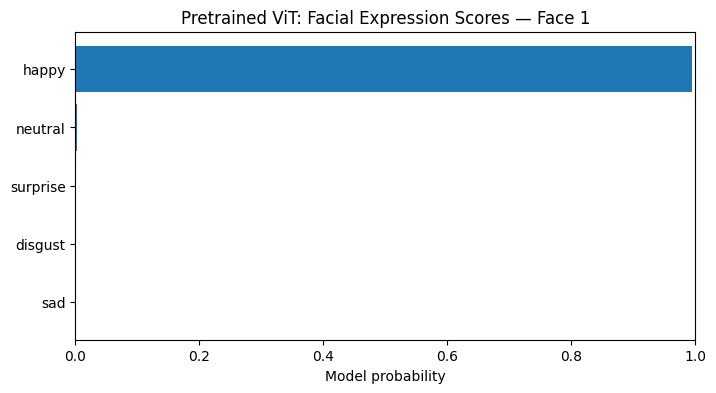

Reminder: an expression prediction does not reveal actual emotional state.


In [22]:
image_rgb = cv2.cvtColor(face_image, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(face_image, cv2.COLOR_BGR2GRAY)
faces = face_detector.detectMultiScale(
    gray, scaleFactor=1.1, minNeighbors=5, minSize=(35, 35)
)

output_image = face_image.copy()
face_results = []
all_predictions = []

if len(faces) == 0:
    print('No frontal face detected by OpenCV. Try a well-lit, front-facing image.')
else:
    for face_number, (x, y, w, h) in enumerate(faces, start=1):
        pad = int(0.15 * max(w, h))
        x1, y1 = max(0, x - pad), max(0, y - pad)
        x2, y2 = min(face_image.shape[1], x + w + pad), min(face_image.shape[0], y + h + pad)
        face_crop = Image.fromarray(image_rgb[y1:y2, x1:x2])

        predictions = emotion_classifier(face_crop, top_k=None)
        predictions = sorted(predictions, key=lambda d: d['score'], reverse=True)
        predicted_expression = str(predictions[0]['label']).strip().lower()
        confidence = float(predictions[0]['score'])

        face_results.append({
            'Face': face_number,
            'Detected expression': predicted_expression,
            'Model confidence': round(confidence, 3)
        })
        all_predictions.append(predictions)

        cv2.rectangle(output_image, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(output_image, f'{predicted_expression}: {confidence:.1%}',
                    (x, max(25, y - 10)), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (0, 255, 0), 2)

    display(pd.DataFrame(face_results))
    for row in face_results:
        normalized = expression_aliases.get(row['Detected expression'], row['Detected expression'])
        print(f"Assistant for face {row['Face']}: " + assistant_messages.get(
            normalized, 'I identified a facial expression. How can I help you?'
        ))

show_bgr(output_image, 'Original pretrained baseline — OpenCV + ViT', figsize=(9, 6))

if all_predictions:
    scores = pd.DataFrame(all_predictions[0]).sort_values('score', ascending=True)
    plt.figure(figsize=(8, 4))
    plt.barh(scores['label'], scores['score'])
    plt.xlabel('Model probability')
    plt.title('Pretrained ViT: Facial Expression Scores — Face 1')
    plt.xlim(0, 1)
    plt.show()

print('Reminder: an expression prediction does not reveal actual emotional state.')